# MiniFASNet intermediate feature visualization — DeepFace

**Teaching notebook | PyTorch forward hooks | Pretrained networks only**

This notebook uses the **actual DeepFace anti-spoofing implementation** (MiniFASNetV2 and MiniFASNetV1SE). You will inspect the crops, feature-map tensors, selected channels, and final class scores. **No training or weight changes occur.**

Sources: [DeepFace](https://github.com/serengil/deepface), [FasNet.py](https://github.com/serengil/deepface/blob/master/deepface/models/spoofing/FasNet.py), [FasNetBackbone.py](https://github.com/serengil/deepface/blob/master/deepface/models/spoofing/FasNetBackbone.py).

**Important:** Feature maps show neural activations, not proven explanations of which spoofing cues the model uses. Class 1 is treated as *genuine* by DeepFace. The other two output classes indicate spoof categories and should not be relabeled as print/screen without verifying the original dataset label semantics.


## 0. Installation

Recommended: Python 3.11 in a dedicated Conda environment. Run the following from a terminal, or uncomment the install line below. The first model load may download pretrained weights. PyTorch is needed for intermediate activations even when your DeepFace recognition backend uses a different runtime.

```bash
conda create -n fasnet-vis python=3.11 -y
conda activate fasnet-vis
python -m pip install deepface torch matplotlib opencv-python numpy pandas ipykernel
python -m ipykernel install --user --name fasnet-vis --display-name "Python (fasnet-vis)"
```

Select **Python (fasnet-vis)** as the notebook kernel. When using a Git clone of DeepFace instead of the PyPI package, install the clone in editable mode from its root and ensure that VS Code uses that environment.


In [4]:
# Optional when not installed yet (run once, then restart kernel):
# %pip install deepface torch matplotlib opencv-python numpy pandas
%pip install torch torchvision

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.3/127.3 MB 8.6 MB/s  0:00:14m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 9.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 6.7 MB/s  0:00:00m eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.3/6.3 MB 9.5 MB/s  0:00:00 eta 0:00:01m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 536.2/536.2 kB 8.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [torchvision] [torchvision]
Note: you may need to restart the kernel to use updated packages.


## 1. Imports and input images

Provide your own consented images. Start with just one genuine image. The other two are optional until you collect them.

In [8]:
import deepface
import sys
import importlib.util

print("Python:", sys.executable)
print("DeepFace location:", deepface.__file__)
print("DeepFace version:", deepface.__version__)

print(
    "FasNet available:",
    importlib.util.find_spec(
        "deepface.models.spoofing.pytorch.FasNet"
    ) is not None
)

Python: /opt/anaconda3/envs/deepface/bin/python
DeepFace location: /Users/matustanonwong/Desktop/Assistant Professor /Fall Semester 2026/研修１/codes/deepface-master/deepface/__init__.py
DeepFace version: 0.0.103
FasNet available: True


In [9]:
from pathlib import Path
import cv2
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from deepface import DeepFace
from deepface.modules import modeling
from deepface.models.spoofing.pytorch.FasNet import crop, Compose, ToTensor

IMAGE_PATHS = {
    "genuine": "dataset_kenshu/Pom.JPG",
    # "printed_photo": "images/printed_photo.jpg",
    # "screen": "images/screen.jpg",
}
DETECTOR_BACKEND = "opencv"  # change to "retinaface" if installed
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())


PyTorch: 2.14.1
CUDA available: False


## 2. Load pretrained MiniFASNet models from DeepFace

DeepFace downloads (if missing) and loads the two pretrained weight files automatically. The returned object exposes `first_model`, `second_model`, and `device`. Its normal `analyze` method fuses the two predictions.

In [10]:
fasnet = modeling.build_model(task="spoofing", model_name="Fasnet")
models = {
    "MiniFASNetV2 (2.7x crop)": (fasnet.first_model, 2.7),
    "MiniFASNetV1SE (4x crop)": (fasnet.second_model, 4.0),
}
for name, (model, scale) in models.items():
    model.eval()
    print(name, "| device:", next(model.parameters()).device,
          "| parameters:", sum(p.numel() for p in model.parameters()))


26-10-18 16:59:20 - 🔗 2.7_80x80_MiniFASNetV2.pth will be downloaded from https://github.com/minivision-ai/Silent-Face-Anti-Spoofing/raw/master/resources/anti_spoof_models/2.7_80x80_MiniFASNetV2.pth to /Users/matustanonwong/.deepface/weights/2.7_80x80_MiniFASNetV2.pth...


Downloading...
From: https://github.com/minivision-ai/Silent-Face-Anti-Spoofing/raw/master/resources/anti_spoof_models/2.7_80x80_MiniFASNetV2.pth
To: /Users/matustanonwong/.deepface/weights/2.7_80x80_MiniFASNetV2.pth
100%|██████████| 1.85M/1.85M [00:00<00:00, 10.3MB/s]


26-10-18 16:59:22 - 🔗 4_0_0_80x80_MiniFASNetV1SE.pth will be downloaded from https://github.com/minivision-ai/Silent-Face-Anti-Spoofing/raw/master/resources/anti_spoof_models/4_0_0_80x80_MiniFASNetV1SE.pth to /Users/matustanonwong/.deepface/weights/4_0_0_80x80_MiniFASNetV1SE.pth...


Downloading...
From: https://github.com/minivision-ai/Silent-Face-Anti-Spoofing/raw/master/resources/anti_spoof_models/4_0_0_80x80_MiniFASNetV1SE.pth
To: /Users/matustanonwong/.deepface/weights/4_0_0_80x80_MiniFASNetV1SE.pth
100%|██████████| 1.86M/1.86M [00:00<00:00, 7.04MB/s]


MiniFASNetV2 (2.7x crop) | device: cpu | parameters: 434560
MiniFASNetV1SE (4x crop) | device: cpu | parameters: 433586


## 3. Examine the model's actual layer names

This prevents errors if DeepFace updates its backbone. The visualizer selects an available subset of named convolution stages rather than assuming every version has identical modules.

In [11]:
for name, (model, _) in models.items():
    print("\n", name)
    for layer_name, module in model.named_children():
        print(f"  {layer_name:16s} {type(module).__name__}")



 MiniFASNetV2 (2.7x crop)
  conv1            Conv_block
  conv2_dw         Conv_block
  conv_23          Depth_Wise
  conv_3           Residual
  conv_34          Depth_Wise
  conv_4           Residual
  conv_45          Depth_Wise
  conv_5           Residual
  conv_6_sep       Conv_block
  conv_6_dw        Linear_block
  conv_6_flatten   Flatten
  linear           Linear
  bn               BatchNorm1d
  drop             Dropout
  prob             Linear

 MiniFASNetV1SE (4x crop)
  conv1            Conv_block
  conv2_dw         Conv_block
  conv_23          Depth_Wise
  conv_3           ResidualSE
  conv_34          Depth_Wise
  conv_4           ResidualSE
  conv_45          Depth_Wise
  conv_5           ResidualSE
  conv_6_sep       Conv_block
  conv_6_dw        Linear_block
  conv_6_flatten   Flatten
  linear           Linear
  bn               BatchNorm1d
  drop             Dropout
  prob             Linear


## 4. Detect one face and reproduce DeepFace's image crops

We detect using `DeepFace.extract_faces` but feed the **original BGR image** to the MiniFASNet preprocessing. This distinction matters: DeepFace's anti-spoofing code passes BGR crops to `ToTensor()`, with **no division by 255**. Passing an already-normalized RGB face crop would change model inputs.

For a fair model comparison, use the same detector for all photographs.

In [12]:
def prepare_image(path):
    image = cv2.imread(str(path))  # BGR, uint8
    if image is None:
        raise FileNotFoundError(path)
    detections = DeepFace.extract_faces(
        img_path=str(path), detector_backend=DETECTOR_BACKEND,
        enforce_detection=True, align=False, anti_spoofing=False
    )
    if len(detections) != 1:
        raise ValueError(f"Expected exactly 1 face in {path}, got {len(detections)}")
    area = detections[0]["facial_area"]
    bbox = (int(area["x"]), int(area["y"]), int(area["w"]), int(area["h"]))
    return image, bbox

def prepare_model_input(image_bgr, bbox, scale, device):
    patch_bgr = crop(image_bgr, bbox, scale, 80, 80)
    tensor = Compose([ToTensor()])(patch_bgr).unsqueeze(0).to(device)
    return patch_bgr, tensor

available_paths = {k: Path(v) for k, v in IMAGE_PATHS.items() if Path(v).is_file()}
if not available_paths:
    print("No images found yet. Put a genuine face at images/genuine.jpg and rerun.")
else:
    print("Found:", available_paths)


Found: {'genuine': PosixPath('dataset_kenshu/Pom.JPG')}


## 5. Forward hooks — save intermediate tensors

In [13]:
PREFERRED_LAYERS = [
    "conv1", "conv2_dw", "conv_3", "conv_4", "conv_5", "conv_6_sep", "conv_6_dw"
]

def infer_with_features(model, image_tensor):
    activations = {}
    handles = []
    available = dict(model.named_modules())
    chosen = [name for name in PREFERRED_LAYERS if name in available]
    if not chosen:
        raise RuntimeError("No expected layers found; inspect the preceding layer list")

    def hook_for(name):
        def hook(module, inputs, output):
            if isinstance(output, torch.Tensor):
                activations[name] = output.detach().cpu().clone()
        return hook

    try:
        for name in chosen:
            handles.append(available[name].register_forward_hook(hook_for(name)))
        model.eval()
        with torch.inference_mode():
            logits = model(image_tensor)
            probabilities = F.softmax(logits, dim=1).detach().cpu().numpy()[0]
    finally:
        for h in handles:
            h.remove()
    return activations, probabilities


## 6. Visualize selected channels for each layer

Each square below is **one channel**, not an RGB image. Color is normalized *within a channel* to help visibility. This means brightness/color is not quantitatively comparable across different channels by default.

In [14]:
def show_feature_maps(activations, model_label, channels=8):
    for layer_name, tensor in activations.items():
        if tensor.ndim != 4:
            print("Skipping non-spatial layer", layer_name, tuple(tensor.shape))
            continue
        feature = tensor[0].numpy()    # (channels, height, width)
        count = min(channels, len(feature))
        ncols = 4
        nrows = int(np.ceil(count / ncols))
        fig, axes = plt.subplots(nrows, ncols, figsize=(11, 2.8 * nrows), squeeze=False)
        for i, ax in enumerate(axes.flat):
            ax.axis("off")
            if i < count:
                ax.imshow(feature[i], cmap="viridis", interpolation="nearest")
                ax.set_title(f"channel {i}", fontsize=9)
        fig.suptitle(f"{model_label} | {layer_name} | shape: {tuple(tensor.shape)}")
        plt.tight_layout()
        plt.show()


## 7. Run visualization on a single face

Input: genuine | bbox (x,y,w,h): (346, 200, 385, 385)

 MiniFASNetV2 (2.7x crop) | class probabilities: [0.0061 0.9903 0.0036]


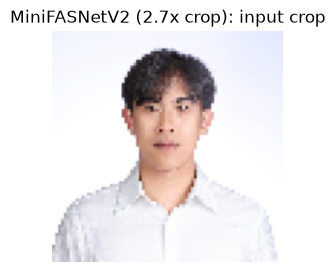

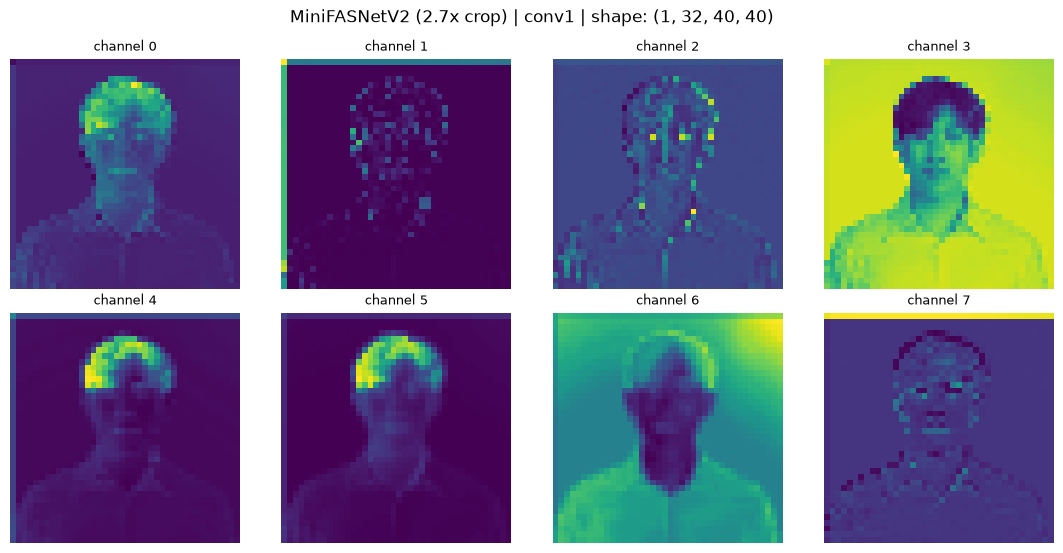

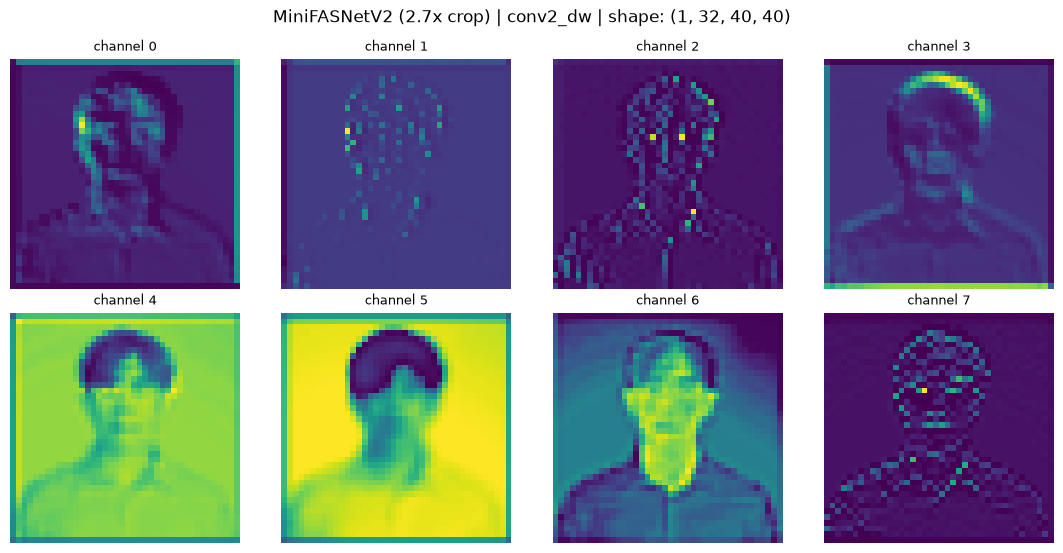

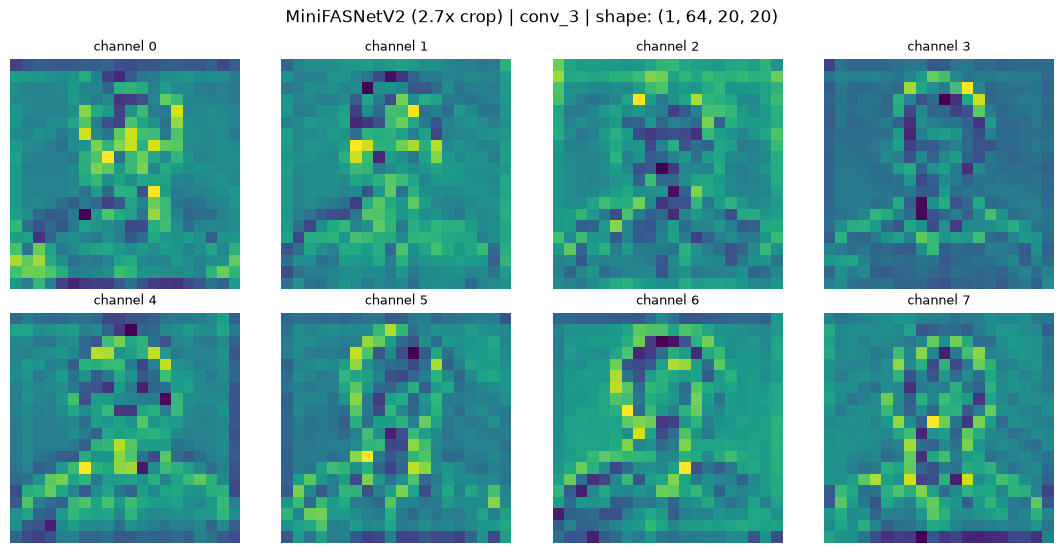

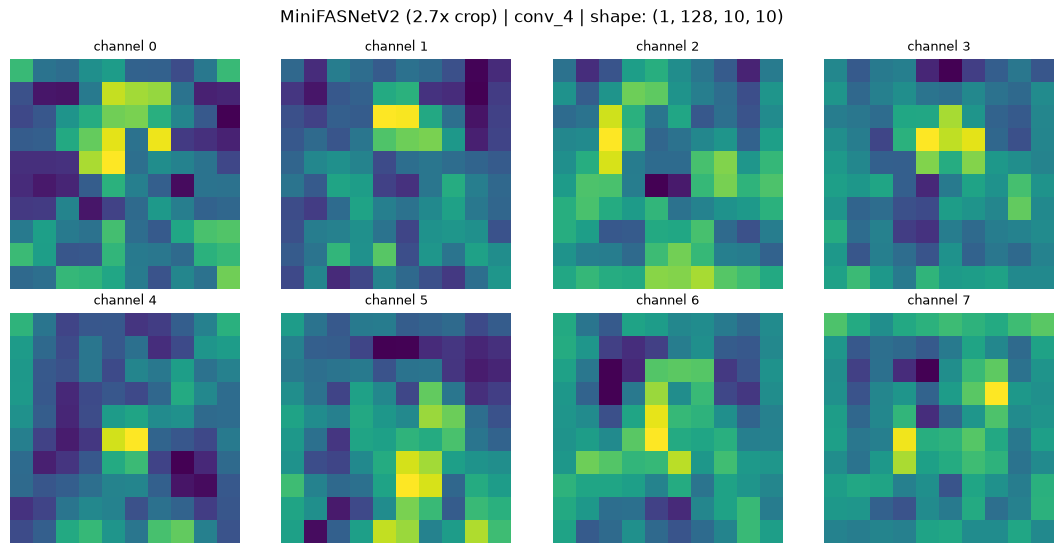

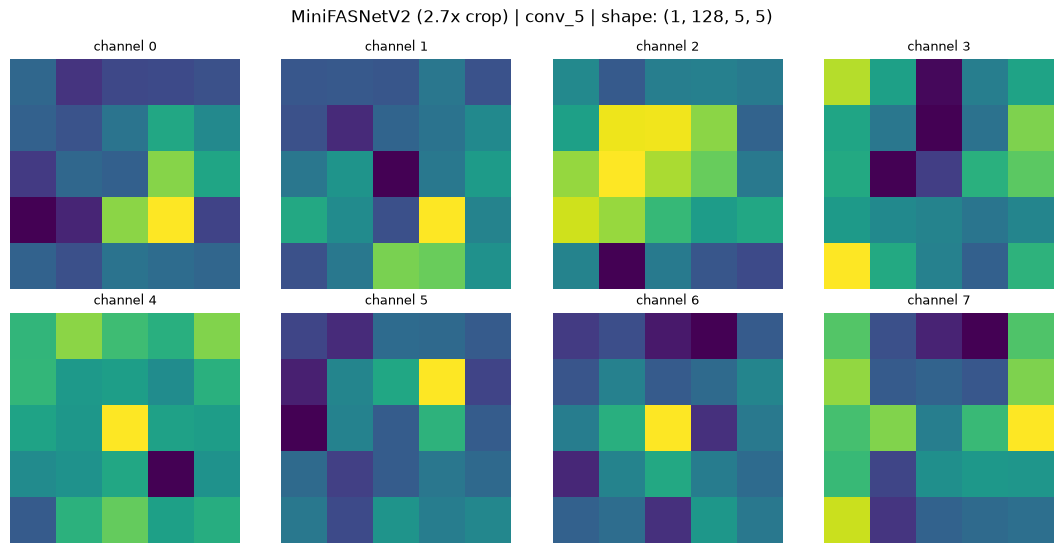

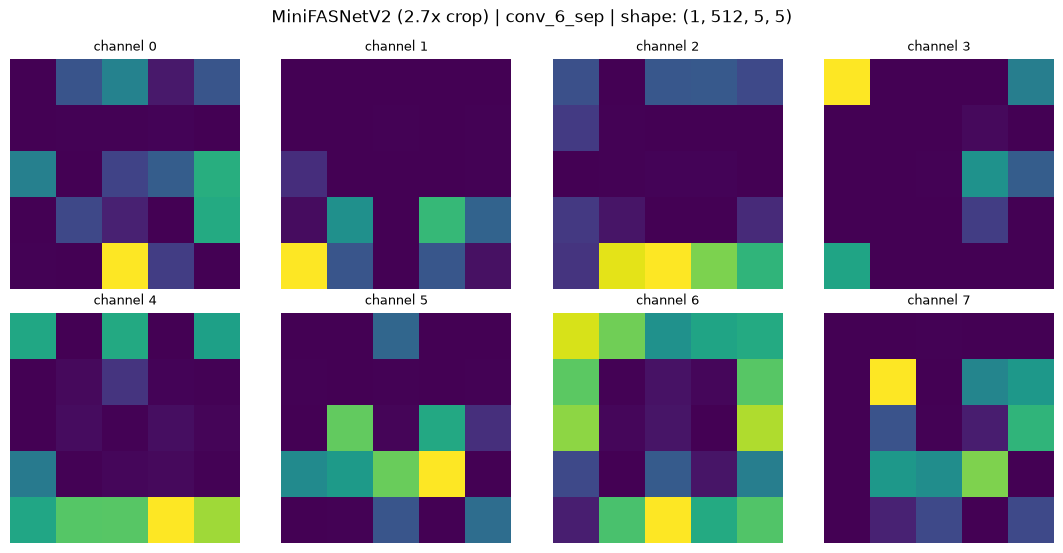

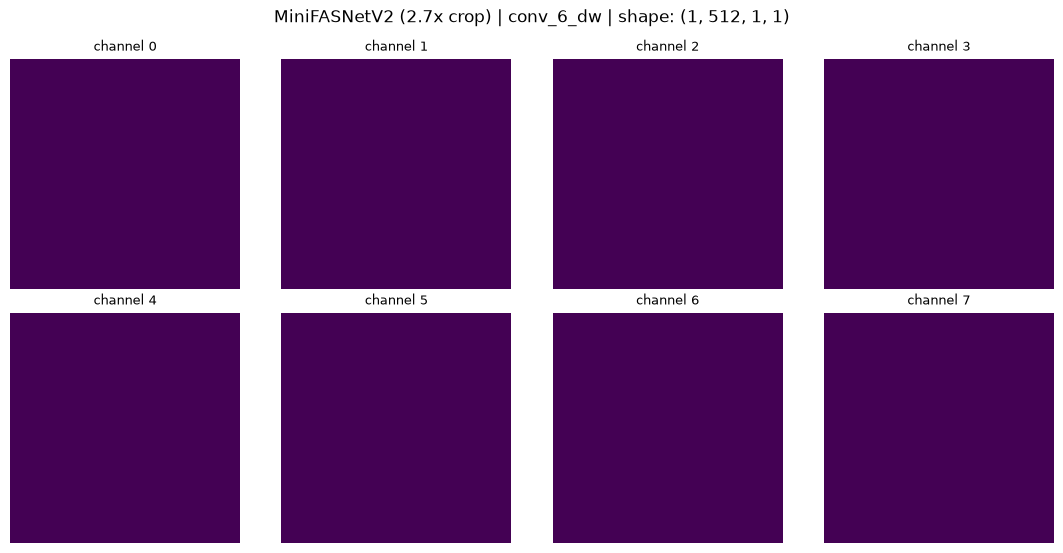


 MiniFASNetV1SE (4x crop) | class probabilities: [5.400e-03 9.942e-01 4.000e-04]


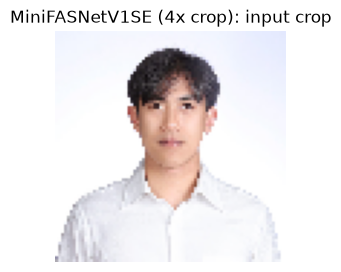

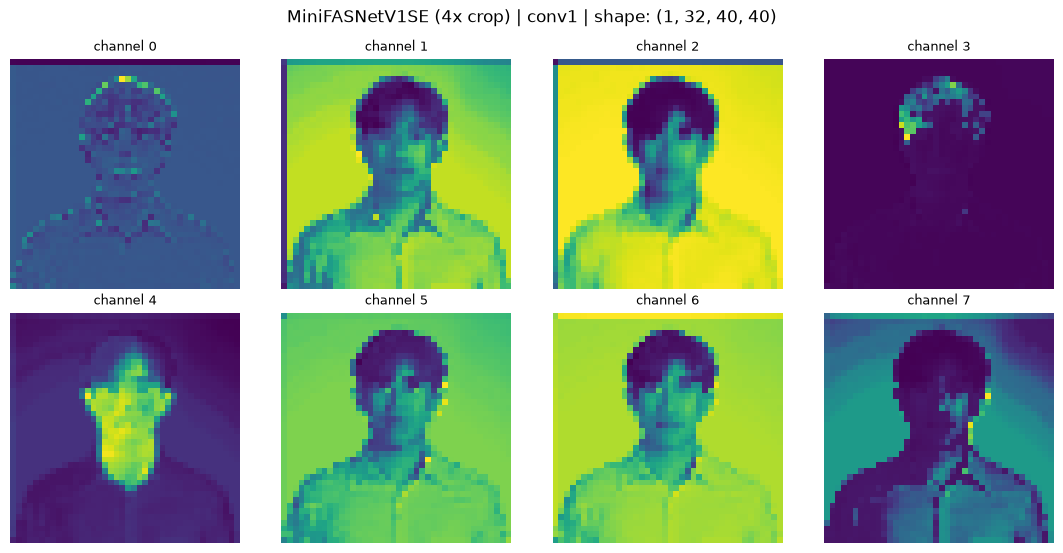

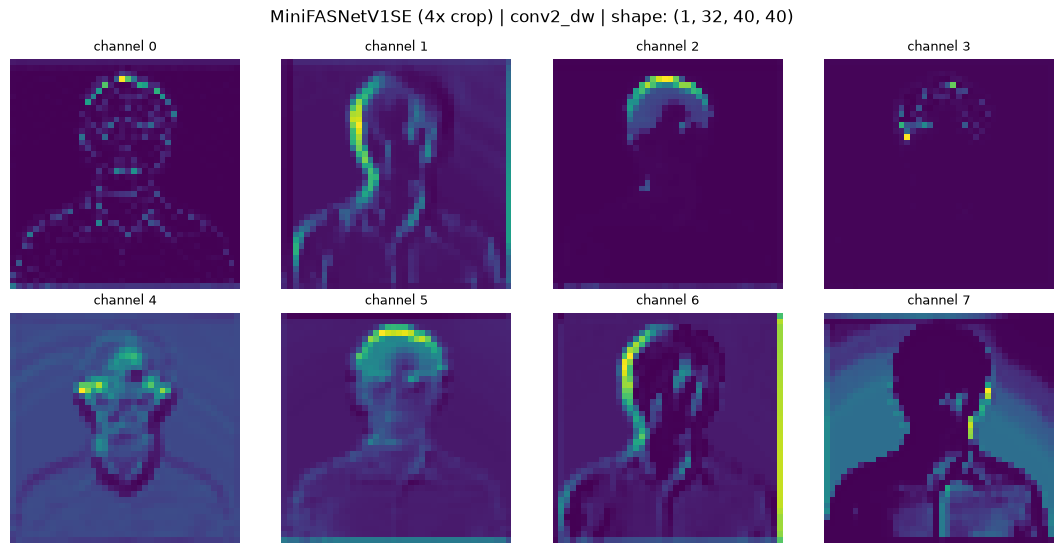

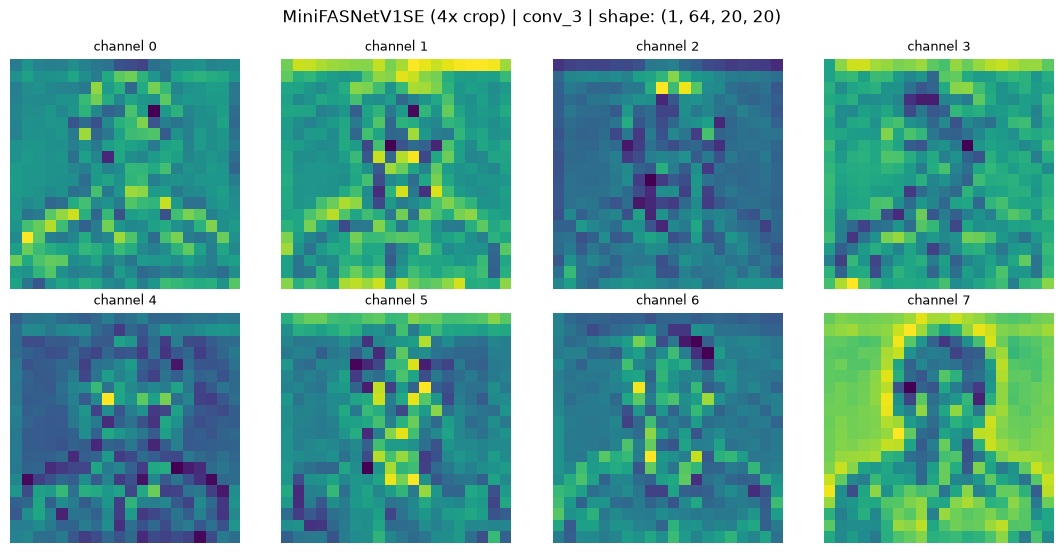

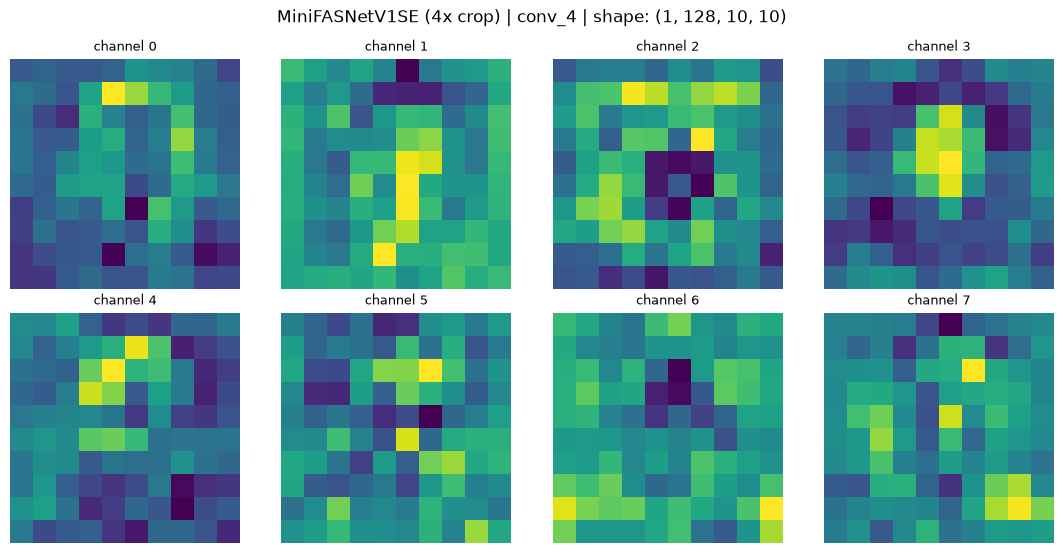

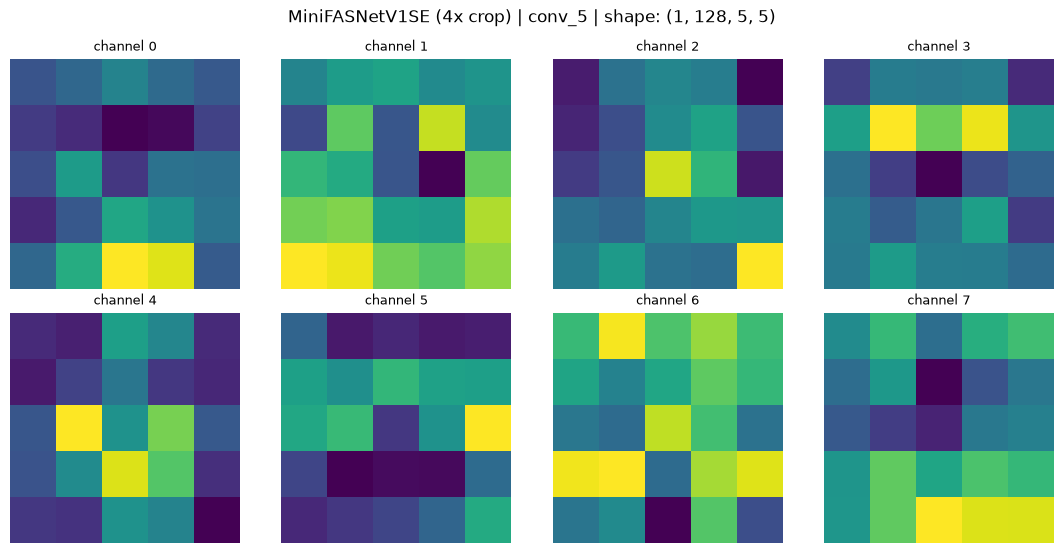

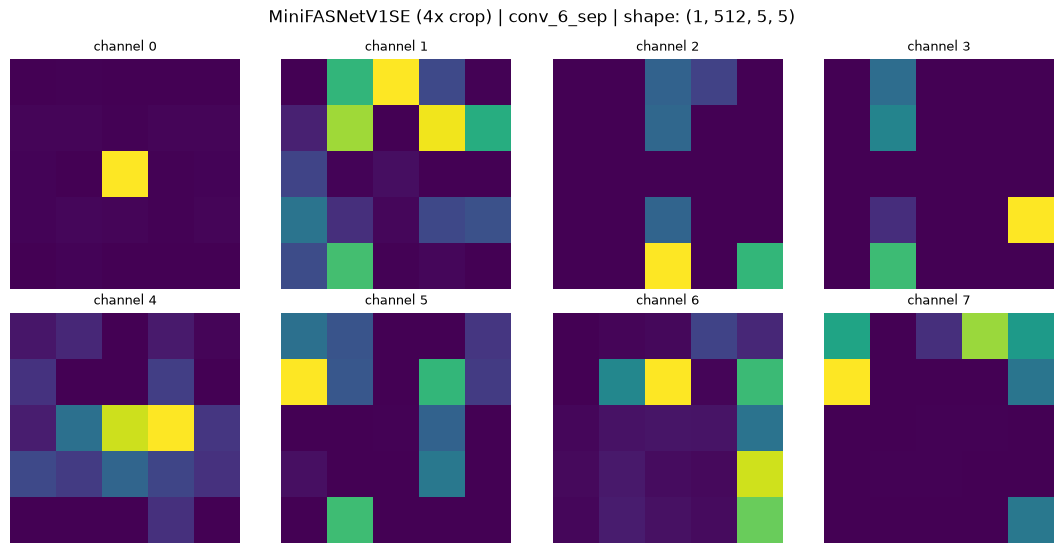

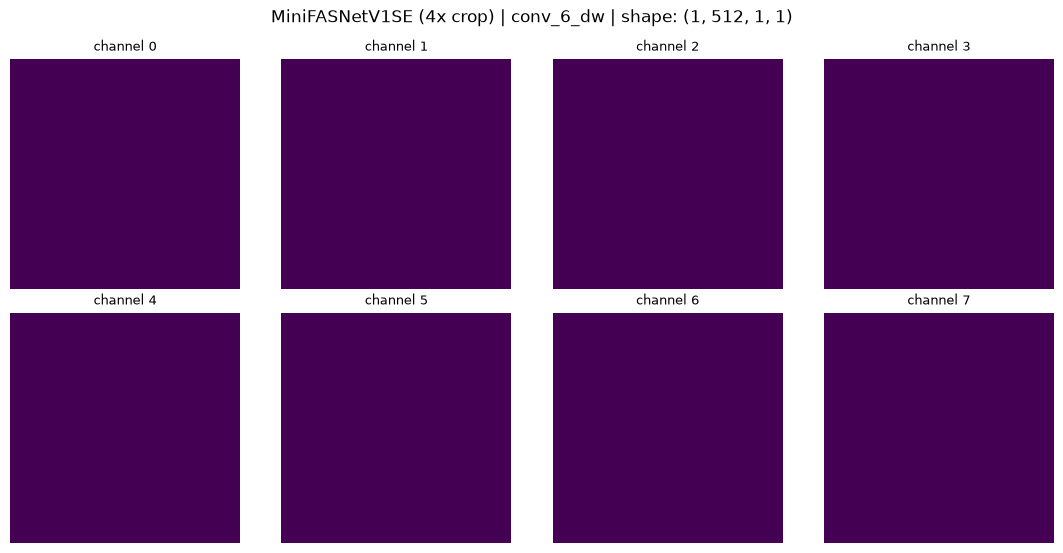

In [15]:
if available_paths:
    label = "genuine" if "genuine" in available_paths else next(iter(available_paths))
    img, bbox = prepare_image(available_paths[label])
    print("Input:", label, "| bbox (x,y,w,h):", bbox)
    all_outputs = {}
    for model_label, (model, scale) in models.items():
        patch, x = prepare_model_input(img, bbox, scale, next(model.parameters()).device)
        activations, probs = infer_with_features(model, x)
        all_outputs[model_label] = probs
        print("\n", model_label, "| class probabilities:", np.round(probs, 4))
        plt.figure(figsize=(3, 3))
        plt.imshow(cv2.cvtColor(patch, cv2.COLOR_BGR2RGB))
        plt.title(f"{model_label}: input crop")
        plt.axis("off")
        plt.show()
        show_feature_maps(activations, model_label)


## 8. Compare class scores and fused decision

As in DeepFace's `Fasnet.analyze`, sum the two 3-class softmax outputs and select the largest combined score. **Class 1 is genuine**. The reported `antispoof_score` equals the selected combined score divided by two, and is not necessarily a calibrated probability.

In [ ]:
if available_paths:
    combined = sum(all_outputs.values())
    predicted_class = int(np.argmax(combined))
    is_real = predicted_class == 1
    score = float(combined[predicted_class] / 2)
    print("Fused output:", np.round(combined / 2, 4))
    print("Predicted class:", predicted_class, "| Is genuine:", is_real, "| Score:", round(score, 4))
    fig, ax = plt.subplots(figsize=(6, 3))
    ax.bar(["class 0", "class 1 (genuine)", "class 2"], combined / 2)
    ax.set_ylim(0, 1)
    ax.set_ylabel("Mean softmax score")
    ax.set_title("DeepFace MiniFASNet ensemble")
    plt.xticks(rotation=12)
    plt.tight_layout()
    plt.show()


## 9. Compare real / printed / screen samples

Execute once all three images exist. It displays the two scale-specific inputs and the final class-score distribution for each image. The code does **not** assume that class 0 means printed or class 2 means screen.

In [ ]:
def evaluate_one(path):
    image, bbox = prepare_image(path)
    patches, scores = [], []
    for name, (model, scale) in models.items():
        patch, x = prepare_model_input(image, bbox, scale, next(model.parameters()).device)
        _, probs = infer_with_features(model, x)
        patches.append(patch)
        scores.append(probs)
    fused = np.mean(scores, axis=0)
    return patches, fused

if len(available_paths) >= 2:
    fig, axes = plt.subplots(len(available_paths), 3, figsize=(12, 3.5 * len(available_paths)), squeeze=False)
    for row, (label, path) in enumerate(available_paths.items()):
        patches, probs = evaluate_one(path)
        for j in range(2):
            axes[row,j].imshow(cv2.cvtColor(patches[j], cv2.COLOR_BGR2RGB))
            axes[row,j].set_title(f"{label} | {list(models)[j]}", fontsize=9)
            axes[row,j].axis("off")
        axes[row,2].bar(["0", "1 (real)", "2"], probs)
        axes[row,2].set_ylim(0, 1)
        axes[row,2].set_title(f"{label}: predicted {'genuine' if np.argmax(probs) == 1 else 'spoof'}")
    plt.tight_layout()
    plt.show()
else:
    print("Add at least two sample images for comparison.")


## 10. Optional: export early-layer feature maps

Feature maps are saved as visual PNGs for lecture slides. The saved colors are per-channel normalized, so don't treat PNG intensities as directly comparable across channels.

In [ ]:
# Example after running cell 7, while the variable `activations` exists:
# outdir = Path("outputs")
# outdir.mkdir(exist_ok=True)
# for layer, tensor in activations.items():
#     if tensor.ndim == 4:
#         plt.imsave(outdir / f"{layer}_channel0.png", tensor[0, 0].numpy(), cmap="viridis")


## Discussion questions for the student

1. What changes between the spatial resolution of early and late feature maps?
2. Why does DeepFace use different crop scales for V2 and V1SE?
3. Do the printed-photo and screen samples produce the same classification scores?
4. If some channels light up strongly around the screen edge, does that prove the classifier relies on the edge? Why or why not?
5. Why can the softmax score be high even when the classification is wrong?
6. How would you evaluate this model on all 600 collected images using APCER, BPCER, and ACER?

**Teaching caveats:** Do not use a screenshot of a digital face as the “screen attack” input; recapture an actual displayed photograph using a camera. For quantitative evaluation, keep recording sessions and participants carefully documented, and report face-detection failures separately.
